# Регрессия — HW

## 1. Загрузка данных и первичный осмотр

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_SEED = 47
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)

plt.rcParams["figure.figsize"] = (12, 8)
sns.set_style("whitegrid")

In [23]:
df = pd.read_csv("Boston.csv", index_col=0)
df.columns = [c.upper() for c in df.columns]
df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,BLACK,LSTAT,MEDV
1,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
2,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
3,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
4,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
5,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


## 2. Размер данных и типы

In [24]:
print("Размер данных:", df.shape)
print("\nТипы по столбцам:")
print(df.dtypes)

Размер данных: (506, 14)

Типы по столбцам:
CRIM       float64
ZN         float64
INDUS      float64
CHAS         int64
NOX        float64
RM         float64
AGE        float64
DIS        float64
RAD          int64
TAX          int64
PTRATIO    float64
BLACK      float64
LSTAT      float64
MEDV       float64
dtype: object


## 3. Проверка пропусков

In [25]:
print("Количество пропусков по столбцам:")
print(df.isnull().sum())
print("\nПропусков итого:", df.isnull().sum().sum())

Количество пропусков по столбцам:
CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
BLACK      0
LSTAT      0
MEDV       0
dtype: int64

Пропусков итого: 0


## 4. Разделение на train и test

In [26]:
X = df.drop(columns=["MEDV"])
y = df["MEDV"]

x_tren, x_test, y_tren, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_SEED, shuffle=True
)

print(f"Размер тренировочной выборки (tren): {x_tren.shape}")
print(f"Размер тестовой выборки (test): {x_test.shape}")

Размер тренировочной выборки (tren): (404, 13)
Размер тестовой выборки (test): (102, 13)


## 5. Baseline-модель

In [27]:
def evaluate_model(ist, pred, imya_modeli="Model"):
    mae = mean_absolute_error(ist, pred)
    rmse = np.sqrt(mean_squared_error(ist, pred))
    r2 = r2_score(ist, pred)
    
    print(f"--- {imya_modeli} ---")
    print(f"MAE:  {mae:.3f}")
    print(f"RMSE: {rmse:.3f}")
    print(f"R²:   {r2:.3f}\n")
    
    return {"mae": mae, "rmse": rmse, "r2": r2}

In [28]:
# базовая модель
model_baseline = LinearRegression()
model_baseline.fit(x_tren, y_tren)

# предсказания на тестовой выборке
y_pred_baseline = model_baseline.predict(x_test)

# показатели качества
pokazately_baseline = evaluate_model(y_test, y_pred_baseline, "Базовая модель (Линейная регрессия)")

--- Базовая модель (Линейная регрессия) ---
MAE:  3.067
RMSE: 4.799
R²:   0.713



## 6. Анализ данных (EDA)

### 6.1. Матрица корреляций

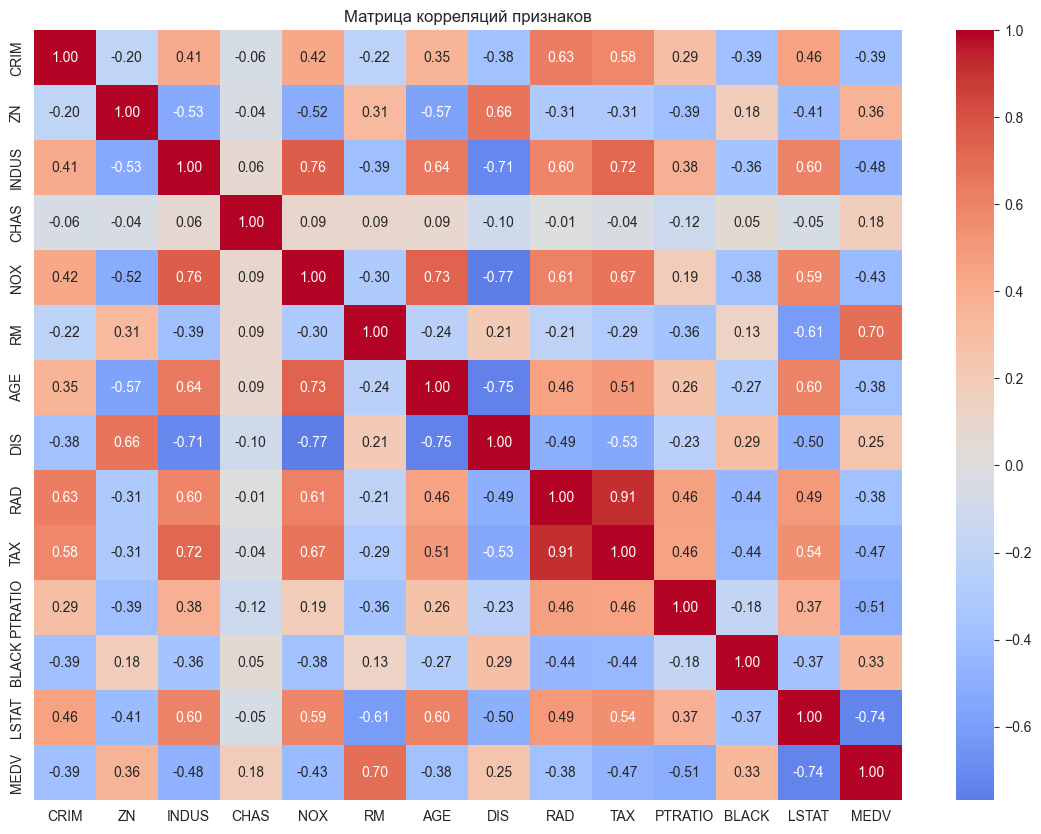

In [29]:
plt.figure(figsize=(14, 10))
corr_matrix = df.corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Матрица корреляций признаков")
plt.show()

### 6.2. Точечные графики ключевых признаков

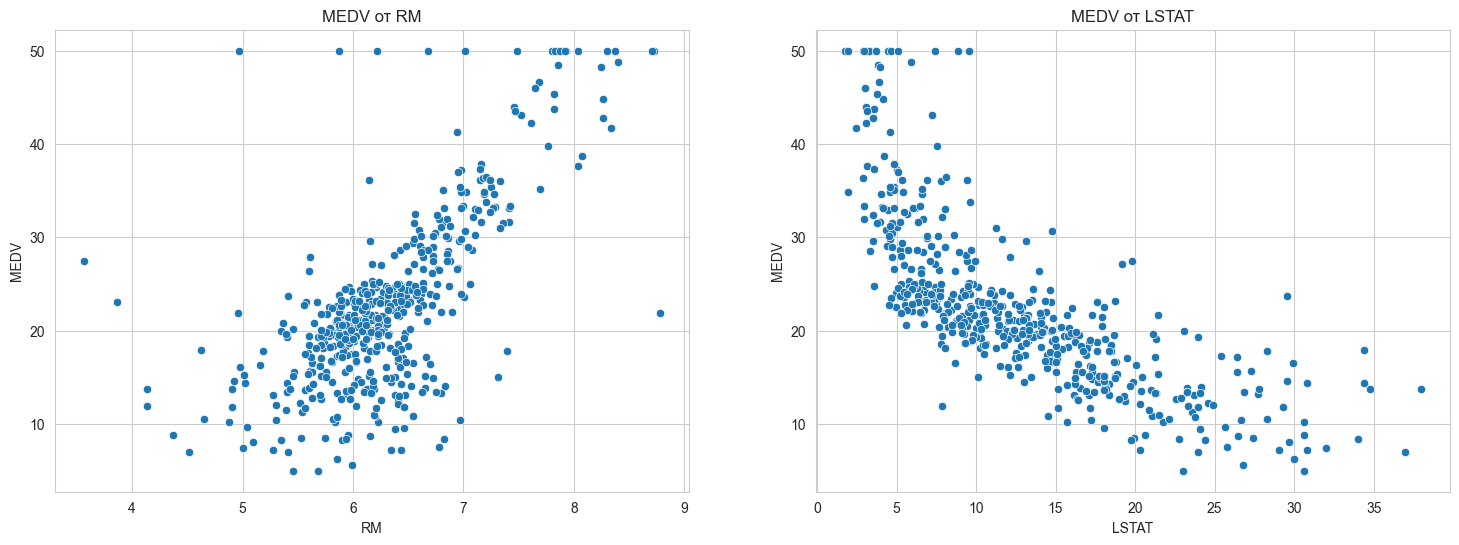

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# график RM - MEDV
sns.scatterplot(x="RM", y="MEDV", data=df, ax=axes[0])
axes[0].set_title("MEDV от RM")

# график LSTAT - MEDV
sns.scatterplot(x="LSTAT", y="MEDV", data=df, ax=axes[1])
axes[1].set_title("MEDV от LSTAT")

plt.show()

### 6.3. Выводы по EDA
- Сильные предикторы: RM (положительная связь), LSTAT (отрицательная).
- Сильная мультиколлинеарность: RAD и TAX (0.91).
- Выбросы в данных упираются в потолок 50.
- Зависимость MEDV от LSTAT нелинейная.

In [31]:
def clean_dataset(df):
    df_copy = df.copy()
    
    # убираем упершиеся в потолок цен
    maska_potolok_50 = df_copy["MEDV"] == 50
    
    # убираем дома где мало комнат
    maska_niz = df_copy["RM"] < 4
    
    # убираем дома с большим количеством комнат, но низкой ценой
    maska_podozr = (df_copy["RM"] > 8) & (df_copy["MEDV"] < 30)
    
    # объединяем все маски
    itogovaya_maska = maska_potolok_50 | maska_niz | maska_podozr
    
    return df_copy.loc[~itogovaya_maska]

In [32]:
# восстанавливаем tren и test фрэймы для очистки
tren_poln = pd.concat([x_tren, y_tren], axis=1)
test_poln = pd.concat([x_test, y_test], axis=1)

# чистим
tren_chis = clean_dataset(tren_poln)
test_chist = clean_dataset(test_poln)

# опять делим на x и y
x_tren_chis = tren_chis.drop(columns=["MEDV"])
y_tren_chis = tren_chis["MEDV"]

x_test_chist = test_chist.drop(columns=["MEDV"])
y_test_chist = test_chist["MEDV"]

print(f"tren до очистки: {tren_poln.shape[0]}")
print(f"tren после очистки: {tren_chis.shape[0]}")
print(f"test до очистки: {test_poln.shape[0]}")
print(f"test после очистки: {test_chist.shape[0]}")

tren до очистки: 404
tren после очистки: 388
test до очистки: 102
test после очистки: 99


## 7. Модель на очищенных данных

In [33]:
# Обучаем модель на очищенных данных
model_na_chityh = LinearRegression()
model_na_chityh.fit(x_tren_chis, y_tren_chis)

# Предсказания на очищенном тесте
y_pred_chist = model_na_chityh.predict(x_test_chist)

# Оценка
pokazately_chist = evaluate_model(y_test_chist, y_pred_chist, "после чистки")

--- после чистки ---
MAE:  2.527
RMSE: 3.507
R²:   0.819



## 8. Предобработка данных (класс)

In [34]:
class DataPreprocessing:
    def __init__(self):
        self.scaler = MinMaxScaler()
        self.columns_order = None

    def fit(self, df):
        df_copy = self._apply_features(df.copy())
        
        # обучаем на признаках
        stolbci = list(df_copy.columns)
        self.scaler.fit(df_copy[stolbci])
        
        # запишем порядок колонок
        self.columns_order = stolbci

    def transform(self, df):
        df_copy = self._apply_features(df.copy())
        
        # применяем к признакам
        stolbci = list(df_copy.columns)
        df_copy[stolbci] = self.scaler.transform(df_copy[stolbci])
        
        # возвращаем в нужном порядке
        return df_copy[self.columns_order]

    def _apply_features(self, df):
        # логарифмируем DIS 
        if "DIS" in df.columns:
            df["DIS_LOG"] = np.log(df["DIS"] + 1e-9)
            df = df.drop(columns=["DIS"])
            
        # полиномиальный признак для LSTAT
        if "LSTAT" in df.columns:
            df["LSTAT_POLY_2"] = df["LSTAT"] ** 2
            
        return df

In [35]:
preproc = DataPreprocessing()

# обучение на tren
preproc.fit(x_tren_chis) 

# применяем к tren и test
x_tren_podg = preproc.transform(x_tren_chis)
x_test_podg = preproc.transform(x_test_chist)

print("Размер признаков после  подготовительной предобработки:", x_tren_podg.shape)
print("Колонки после подготовки:")
print(x_tren_podg.columns.tolist())

Размер признаков после  подготовительной предобработки: (388, 14)
Колонки после подготовки:
['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'RAD', 'TAX', 'PTRATIO', 'BLACK', 'LSTAT', 'DIS_LOG', 'LSTAT_POLY_2']


## 9. Модель после предобработки

In [36]:
# обучаем на подготовленных данных
model_podg = LinearRegression()
model_podg.fit(x_tren_podg, y_tren_chis)

# редсказания на подготовленном тесте
y_pred_podg = model_podg.predict(x_test_podg)

# Оценка
podg_metrics = evaluate_model(y_test_chist, y_pred_podg, "после  подготовительной предобработки")

--- после  подготовительной предобработки ---
MAE:  2.262
RMSE: 3.151
R²:   0.854



## 10. Сводная таблица метрик

In [37]:
rezult_df = pd.DataFrame([
    {"шаг": "1. базовая", **pokazately_baseline},
    {"шаг": "2. чистка", **pokazately_chist},
    {"шаг": "3. предобработка", **podg_metrics},
])

rezult_df.columns = ["шаг", "MAE", "RMSE", "R²"]

# округлим 
rezult_df = rezult_df.round(3)

print(rezult_df.to_string(index=False))

             шаг   MAE  RMSE    R²
      1. базовая 3.067 4.799 0.713
       2. чистка 2.527 3.507 0.819
3. предобработка 2.262 3.151 0.854


## 11. Дополнительно: Lasso-регрессия и отбор признаков

In [38]:
# создаём Lasso 
model_lasso = Lasso(alpha=0.01, random_state=RANDOM_SEED)
model_lasso.fit(x_tren_podg, y_tren_chis)

# смотрим веса признаков
vesa = pd.Series(model_lasso.coef_, index=x_tren_podg.columns)
print(vesa.sort_values(key=abs, ascending=False).round(4))

print("\nПризнаки с нулевым весом:")
print(vesa[vesa == 0].index.tolist())

LSTAT          -26.6320
LSTAT_POLY_2    20.1163
RM              20.0906
CRIM           -10.1293
DIS_LOG         -8.8399
PTRATIO         -6.5580
TAX             -6.3333
NOX             -5.3392
RAD              3.9746
BLACK            3.3683
AGE             -2.3202
CHAS             0.8840
INDUS           -0.6804
ZN               0.0000
dtype: float64

Признаки с нулевым весом:
['ZN']


## 12. Удаление неважных признаков и финальная модель

In [39]:
# удаляем признаки с нулевым весом из tren и test
x_tren_itog = x_tren_podg.drop(columns=["ZN"])
x_test_itog = x_test_podg.drop(columns=["ZN"])

# обучаем финальную модель
model_itog = LinearRegression()
model_itog.fit(x_tren_itog, y_tren_chis)

# предсказания
y_pred_itog = model_itog.predict(x_test_itog)

# оценка
pokazately_itog = evaluate_model(y_test_chist, y_pred_itog, "без признаков с нулевым весом")

# Добавим в таблицу
rezult_df = pd.concat([
    rezult_df,
    pd.DataFrame([{"шаг": "4. без признаков с нулевым весом",
                   "MAE": pokazately_itog["mae"],
                   "RMSE": pokazately_itog["rmse"],
                   "R²": pokazately_itog["r2"]}])
], ignore_index=True)
rezult_df = rezult_df.round(3)
print("\nОбновлённая сводная таблица:")
print(rezult_df.to_string(index=False))

--- без признаков с нулевым весом ---
MAE:  2.261
RMSE: 3.152
R²:   0.854


Обновлённая сводная таблица:
                             шаг   MAE  RMSE    R²
                      1. базовая 3.067 4.799 0.713
                       2. чистка 2.527 3.507 0.819
                3. предобработка 2.262 3.151 0.854
4. без признаков с нулевым весом 2.261 3.152 0.854


## 13. Анализ ошибок модели

In [40]:
# соберем предсказаниям, истинные значения и ошибки
oshibki_df = pd.DataFrame({
    "ist": y_test_chist,
    "pred": y_pred_itog,
    "oshibka": y_test_chist - y_pred_itog,
    "abs_oshibka": np.abs(y_test_chist - y_pred_itog)
}).sort_values("abs_oshibka", ascending=False)

# выведем худшие предсказания
print("10 записей с наибольшей абсолютной ошибкой:")
print(oshibki_df.head(10).round(2))

10 записей с наибольшей абсолютной ошибкой:
      ist   pred  oshibka  abs_oshibka
408  27.9  17.20    10.70        10.70
400   6.3  15.58    -9.28         9.28
204  48.5  39.30     9.20         9.20
158  41.3  32.42     8.88         8.88
254  42.8  35.37     7.43         7.43
191  37.0  30.47     6.53         6.53
283  46.0  39.59     6.41         6.41
423  20.8  15.10     5.70         5.70
386   7.2  12.52    -5.32         5.32
302  22.0  26.91    -4.91         4.91


## 14. Выводы

Во время выполнения работы базовая модель прошла несколько этапов улучшения:
1. Базовая модель(Линейная регрессия) показал MAE = 3.067, R² = 0.713.
2. Очистка выбросов (MEDV == 50, RM < 4, RM > 8 & MEDV < 30) улучшила показатель: MAE = 2.527, R² = 0.819. Это связано с удалением цензурированных данных и аномалий.
3. Подготовительная предобработка (логарифмирование DIS, полином LSTAT², MinMaxScaler) дала ещё больший прирост показателей: MAE = 2.262, R² = 0.854.
4. Отбор признаков через Lasso показал, что признак ZN имеет нулевой вес. Удаление ZN мало повлияло на модель
5. Итоговая модель имеет MAE = 2.261, R² = 0.854

Самые большие ошибки модель допускает на домах с ценой, близкой к потолку (около 50), и на объектах с нестандартными комбинациями признаков.